# 3. Running the Published NF-κB Model (NEMO/IKK & NIK Inputs)

Now let's put **everything** you learned in Chapters 1 and 2 together to build and simulate a real, peer-reviewed Mitchell Lab model: the **multi-dimer NF-κB signalling model** from Jayawant *et al.* ([`SiFTW/NFkBModel`](https://github.com/SiFTW/NFkBModel))!

Instead of 3 toy proteins, this published model tracks **101 molecular species**, **427 biochemical reactions**, and **257 parameters** — including all five NF-κB subunits (`RelA`, `RelB`, `cRel`, `p50`, `p52`), four IκB inhibitors (`IkBa`, `IkBb`, `IkBe`, `IkBd`), the precursor `p100`, nuclear/cytoplasmic shuttling, and transcriptional feedback loops (full-scale versions of the NF-κB/IκB feedback you started building in Tutorial 2!).

:::{note} Single-module NF-κB today; multi-module receptors next!
In this tutorial we run the standalone published **NF-κB module** from [`SiFTW/NFkBModel`](https://github.com/SiFTW/NFkBModel) driven directly by time-dependent **NEMO/IKK** and **NIK** input curves. Combining multiple upstream receptor modules (like BCR + TLR + NF-κB in Figure 5 of the paper) will be our focus in the next tutorial!
:::

---

## The Biology: Two Distinct Inputs, Two Distinct NF-κB Dimers

NF-κB signalling operates through **two major branches** — and our published model captures both at once:

```{figure} ../images/nfkb-canonical-noncanonical.svg
:alt: Canonical NEMO/IKK input activates nuclear RelA:p50 rapidly, while non-canonical NIK stabilisation activates nuclear RelB:p52 over hours
:width: 100%

How the two time-dependent inputs control the published NF-κB model: **NEMO/IKK** drives rapid nuclear **RelA:p50 (`RelAnp50n`)**, while **NIK stabilisation** drives slower, sustained nuclear **RelB:p52 (`RelBnp52n`)**.
```

1. **Canonical pathway — NEMO/IKK input (`ikk1_ikkactivity`) → Nuclear RelA:p50 (`RelAnp50n`):**
   - At rest, only **1%** of NEMO/IKK is active (`basalIKK = 1.4 nM` out of `totalIKK = 140 nM`).
   - When a canonical stimulus arrives (e.g. TNF, BCR, or TLR), `ikk1_ikkactivity(t)` spikes rapidly toward `140 nM`, triggering fast degradation of **IκBα/β/ε** and releasing **RelA:p50** into the nucleus (`RelAnp50n`) within minutes!
   - Just like in Tutorial 2, nuclear RelA:p50 then induces fresh **IκBα** synthesis, pulling RelA:p50 back down in classic negative-feedback adaptation.

2. **Non-canonical pathway — NIK input (`nik_deg_mod`) → Nuclear RelB:p52 (`RelBnp52n`):**
   - Unlike IKK, `nik_deg_mod(t)` acts in the opposite direction:
   - In a resting cell, the kinase **NIK** is **constantly being made** *and* **constantly being destroyed** (`Rate = k1_NIKConstDeg * NIK * nik_deg_mod(t)` with `nik_deg_mod(t) = 1.0`, i.e. 100% destruction), so NIK levels stay tiny.
   - When a non-canonical stimulus arrives (such as **BAFF** or **CD40L**), it **switches OFF NIK degradation** — meaning **`nik_deg_mod(t)` drops from `1.0` down toward `0.0`**!
   - Because NIK is still being synthesized while destruction is blocked, **NIK builds up**, processes **`p100` into `p52`** (and degrades IκBδ), and sends **RelB:p52 (`RelBnp52n`)** steadily into the nucleus over many hours!

---

## Step 1: Inspect the Published NF-κB CSV Files

The exact `SiFTW/NFkBModel` CSV definition files are already pre-loaded in your workspace under `NFkB/moduleDefinitionFiles/NFkB/`.

Let's inspect them with `CSV.jl` and `DataFrames.jl` — and verify that the **exact same `CSV2Julia` rules** from Chapters 1 and 2 are at work!

In [1]:
using DifferentialEquations
using Plots
using CSV
using DataFrames

gr()

# Paths to the published NF-kB model CSVs (matching SiFTW/NFkBModel)
rxn_file   = "NFkB/moduleDefinitionFiles/NFkB/reactions.csv"
param_file = "NFkB/moduleDefinitionFiles/NFkB/parameters.csv"
law_file   = "NFkB/moduleDefinitionFiles/NFkB/rateLaws.csv"

rxns_df   = CSV.read(rxn_file, DataFrame; stripwhitespace=true)
params_df = CSV.read(param_file, DataFrame; stripwhitespace=true)
laws_df   = CSV.read(law_file, DataFrame; stripwhitespace=true)

println("Published NF-κB model size:")
println("  Reactions:  ", nrow(rxns_df))
println("  Parameters: ", nrow(params_df))
println("  Rate laws:  ", nrow(laws_df))

# Spot the time-dependent parameters using the (t) rule from Chapter 2!
println("\nTime-dependent input parameters in parameters.csv:")
display(filter(row -> occursin("(t)", string(row[2])), params_df))

# Peek at how reactions.csv uses those two input parameters!
println("\nSample IKK- and NIK-driven reactions in reactions.csv:")
display(first(filter(row -> occursin("ikk1_ikkactivity", string(row[5])) || occursin("nik_deg_mod", string(row[5])), rxns_df), 8))

Published NF-κB model size:
  Reactions:  427
  Parameters: 257
  Rate laws:  93

Time-dependent input parameters in parameters.csv:


Row,parameter,value,distribute
,DataStri…,DataStri…,Int64
1,ikk1_ikkactivity,t->ikkFunc(t),0
2,nik_deg_mod,t->NIKFunc(t),0



Sample IKK- and NIK-driven reactions in reactions.csv:


Row,Substrate,Products,Kinetic Law,Modifiers,Parameters
,DataStri…?,DataStri…?,DataStri…,DataStri…?,DataStri…
1,RelAp50IkBa,RelAp50,Mass Action IKK,missing,k1_IkBaDegIKK ikk1_ikkactivity
2,RelAp50IkBb,RelAp50,Mass Action IKK,missing,k1_IkBbDegIKK ikk1_ikkactivity
3,RelAp50IkBe,RelAp50,Mass Action IKK,missing,k1_IkBeDegIKK ikk1_ikkactivity
4,RelBp50IkBa,RelBp50,Mass Action IKK,missing,k1_IkBaDegIKK ikk1_ikkactivity
5,RelBp50IkBb,RelBp50,Mass Action IKK,missing,k1_IkBbDegIKK ikk1_ikkactivity
6,RelBp50IkBe,RelBp50,Mass Action IKK,missing,k1_IkBeDegIKK ikk1_ikkactivity
7,RelBp52IkBa,RelBp52,Mass Action IKK,missing,k1_IkBaDegIKK ikk1_ikkactivity
8,RelBp52IkBb,RelBp52,Mass Action IKK,missing,k1_IkBbDegIKK ikk1_ikkactivity


In those two tables, you can see how both inputs use the same rules from Chapters 1 and 2:
- `ikk1_ikkactivity` has value `t->ikkFunc(t)` and matches `{ikk1}` in `Mass Action IKK` (`{k1} * [s1] * {ikk1}`).
- `nik_deg_mod` has value `t->NIKFunc(t)` and matches `{nik}` in `Mass Action NIK` (`{k1} * [s1] * {nik}`).

The same naming and `(t)` conventions apply whether a model has 4 reactions or 427.

---

## Step 2: Generate the 101-Species Julia ODE Model in `param` Mode

Let's run `csv2model-multiscale.py` in **`param` mode** to generate `nfkbModel.jl`, `variableNames.jl`, and `scanIncludes.jl`!

In [2]:
run(`python3 csv2model-multiscale.py $rxn_file $param_file $law_file nfkbModel.jl param`)

include("nfkbModel.jl")
include("variableNames.jl")
include("scanIncludes.jl")

# Look up the indices of our two inputs and two key nuclear readouts
ikkIndex   = findfirst(x -> x == "ikk1_ikkactivity", parameterNameList)
nikIndex   = findfirst(x -> x == "nik_deg_mod", parameterNameList)

idx_RelAp50 = findfirst(x -> x == "RelAnp50n", syms)
idx_RelBp52 = findfirst(x -> x == "RelBnp52n", syms)
idx_IkBa    = findfirst(x -> x == "IkBa", syms)
idx_NIK     = findfirst(x -> x == "NIK", syms)

println("\nModel built successfully!")
println("  Species count:   ", length(syms))
println("  Parameter count: ", length(parameterNameList))
println("  ikk1_ikkactivity -> paramVals[", ikkIndex, "]")
println("  nik_deg_mod      -> paramVals[", nikIndex, "]")
println("  Nuclear RelA:p50 (RelAnp50n) -> syms[", idx_RelAp50, "]")
println("  Nuclear RelB:p52 (RelBnp52n) -> syms[", idx_RelBp52, "]")

param
Running CSV2JuliaDiffEq with parameters dynamically determined by a variable, re-run with the 5th argument set to 'scan' or 'inline'
Opening NFkB/moduleDefinitionFiles/NFkB/rateLaws.csv as rate law file
Opening NFkB/moduleDefinitionFiles/NFkB/parameters.csv as parameters file
Opening NFkB/moduleDefinitionFiles/NFkB/reactions.csv as reactions file


parameters can now be searched in parameterNameList by name.
example to modify k_binding 1.5 fold higher:
indexOfParam=findfirst(x->"k_binding"==x,parameterNameList)
paramVals[indexOfParam]=paramVals[indexOfParam]*1.5



Model built successfully!
  Species count:   101
  Parameter count: 257
  ikk1_ikkactivity -> paramVals[252]
  nik_deg_mod      -> paramVals[253]
  Nuclear RelA:p50 (RelAnp50n) -> syms[6]
  Nuclear RelB:p52 (RelBnp52n) -> syms[14]


---

## Step 3: Define the NEMO/IKK and NIK Time-Dependent Input Curves

Let's create our resting (**steady-state**, `SS`) and stimulated (**time-course**, `TC`) input curves directly following `SiFTW/NFkBModel`:

- **Canonical NEMO/IKK input:**
  - Resting (`ikkSS`): constant `1%` of `totalIKK = 140 nM` (`1.4 nM`)
  - Stimulated (`ikkTC`): `basalIKK + ikkDefault(t, maxTimeTC) * totalIKK` — spikes rapidly to `~141 nM` at 10 min, then settles to a lower plateau!
- **Non-canonical NIK input:**
  - Resting (`nikSS`): `t -> 1.0` (100% NIK degradation → NIK stays near zero)
  - Stimulated (`nikTC`): `t -> 0.0` (blocks NIK degradation completely, just like `NIKFuncTC = t -> 0` in `SiFTW/NFkBModel`, letting NIK accumulate and process `p100` into `p52`!)

Let's define and plot both input curves over a **24-hour** time course (`24 * 60 = 1440` minutes — long enough to see both the rapid canonical RelA:p50 spike and the slower non-canonical RelB:p52 build-up!).

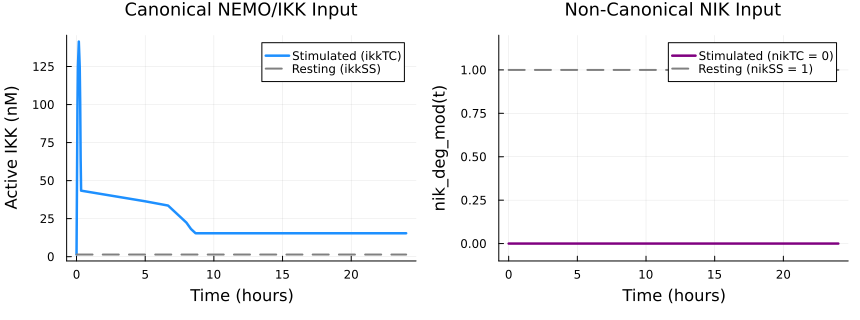

In [3]:
totalIKK  = 140.0
basalIKK  = totalIKK / 100.0   # 1% active IKK at rest (1.4 nM)
maxTimeSS = 1000.0 * 60.0      # 1,000 hours (in minutes) to reach resting steady state
maxTimeTC = 24.0 * 60.0        # 24-hour stimulated time course (1440 min)

# Exact experimental NEMO/IKK curve from SiFTW/NFkBModel (piecewise linear interpolation)
function ikkDefault(t, maxTime)
    IKKparamVals = [0, 85, 100, 85, 45, 30, 25, 23, 18, 15, 12, 10, 10] ./ 100.0
    paramTime    = [0, 5, 10, 15, 18, 20, 300, 400, 450, 480, 500, 520, max(maxTime, 2880.0)]
    indexGTTime  = min(searchsortedfirst(paramTime, t), length(paramTime))
    indexLTTime  = max(1, indexGTTime - 1)
    timeDiff     = paramTime[indexGTTime] - paramTime[indexLTTime]
    if timeDiff > 0
        gradient = (IKKparamVals[indexGTTime] - IKKparamVals[indexLTTime]) / timeDiff
        return IKKparamVals[indexLTTime] + gradient * (t - paramTime[indexLTTime])
    else
        return IKKparamVals[indexLTTime]
    end
end

# Steady-state (resting) input functions
ikkSS = t -> basalIKK
nikSS = t -> 1.0      # 100% NIK degradation at rest

# Dynamic (stimulated) input functions
ikkTC = t -> basalIKK + ikkDefault(t, maxTimeTC) * totalIKK
nikTC = t -> 0.0      # NIK degradation blocked -> NIK stabilises & accumulates!

# Plot both inputs (converting minutes -> hours on the x-axis for readability)
t_mins = 0.0:2.0:maxTimeTC
t_hrs  = t_mins ./ 60.0

p_ikk = plot(t_hrs, ikkTC.(t_mins), lw=2.5, color=:dodgerblue, label="Stimulated (ikkTC)",
             title="Canonical NEMO/IKK Input", titlefontsize=12,
             xlabel="Time (hours)", ylabel="Active IKK (nM)")
plot!(p_ikk, t_hrs, ikkSS.(t_mins), lw=2.0, ls=:dash, color=:gray, label="Resting (ikkSS)")

p_nik = plot(t_hrs, nikTC.(t_mins), lw=2.5, color=:purple, ylim=(-0.1, 1.2), label="Stimulated (nikTC = 0)",
             title="Non-Canonical NIK Input", titlefontsize=12,
             xlabel="Time (hours)", ylabel="nik_deg_mod(t)")
plot!(p_nik, t_hrs, nikSS.(t_mins), lw=2.0, ls=:dash, color=:gray, label="Resting (nikSS = 1)")

plot(p_ikk, p_nik, layout=(1, 2), size=(860, 320))

---

## Step 4: Two-Phase Simulation (Steady State → Time Course) & Stiff Solvers

Before we call `solve(...)` on this 101-species model, there are **two important concepts** used in most signalling simulations:

### 1. Why run in Two Phases?

If we started all 101 proteins at `0 nM` and immediately hit the cell with IKK or NIK, the cell would have no resting `RelA`, no `p100`, no `IκBα` — nothing! Instead, we mirror what happens in a wet-lab experiment:

```{figure} ../images/two-phase-simulation.svg
:alt: Two-phase simulation diagram: Phase 1 equilibrates the resting cell to steady state, Phase 2 starts from that resting state and applies dynamic inputs
:width: 100%

**Two-phase workflow:** First let the virtual cell settle to its natural resting balance (**Steady State**), then use those exact resting concentrations (`y0_ss`) as the starting point for every stimulated **Time Course**!
```

### 2. Why do we pass `Rodas5P(autodiff=AutoFiniteDiff())` to `solve(...)`?

A 101-species biochemical network is **"stiff"**, meaning some reactions occur on **sub-second timescales** (such as protein binding) while others take **many hours** (such as processing `p100` into `p52`).
- A standard non-stiff ODE solver must take very small time steps to remain stable on the fast reactions, which makes a 24-hour simulation slow.
- A **stiff ODE solver** such as **`Rodas5P`** is designed to handle both fast and slow timescales together in a few seconds.
- Passing **`autodiff=AutoFiniteDiff()`** tells `Rodas5P` to estimate derivatives numerically rather than using automatic differentiation through `paramVals` (which contains both numbers and `t -> ...` functions). *(Julia may print a yellow performance warning about mixed parameter types; this is expected and harmless when `paramVals` contains both numbers and functions.)*

Let's run **Phase 1 (Steady State)** right now and inspect our resting virtual B-cell!

In [4]:
# Helper to pick a fast stiff solver compatible with mixed numeric + function paramVals
stiff_alg = if isdefined(Main, :AutoFiniteDiff)
    Rodas5P(autodiff=AutoFiniteDiff())
elseif isdefined(DifferentialEquations, :AutoFiniteDiff)
    Rodas5P(autodiff=DifferentialEquations.AutoFiniteDiff())
else
    Rodas5P(autodiff=false)
end

# Phase 1: Equilibrate the resting cell to steady state
p_ss = copy(paramVals)
p_ss[ikkIndex] = ikkSS
p_ss[nikIndex] = nikSS

y0_empty = zeros(length(syms))
prob_ss  = ODEProblem(ODEFunction(nfkbModel), y0_empty, (0.0, maxTimeSS), p_ss)
sol_ss   = solve(prob_ss, stiff_alg; saveat=1000.0)

# Extract the resting cell's 101 concentrations (clamping tiny negative numerical dust to 0)
y0_ss = max.(collect(Float64, sol_ss.u[end]), 0.0)

println("Steady state reached! Resting levels in our unstimulated virtual cell:")
println("  Nuclear RelA:p50 (RelAnp50n) = ", round(y0_ss[idx_RelAp50], digits=3), " nM")
println("  Nuclear RelB:p52 (RelBnp52n) = ", round(y0_ss[idx_RelBp52], digits=3), " nM")
println("  Cytoplasmic IkBa (IkBa)      = ", round(y0_ss[idx_IkBa], digits=3), " nM")
println("  NIK kinase (NIK)             = ", round(y0_ss[idx_NIK], digits=4), " nM")

┌ Warning: Using arrays or dicts to store parameters of different types can hurt performance.
│ Consider using tuples instead.
└ @ SciMLBase /tmp/julia-depot/packages/SciMLBase/Zzjmy/src/performance_warnings.jl:33


Steady state reached! Resting levels in our unstimulated virtual cell:
  Nuclear RelA:p50 (RelAnp50n) = 3.326 nM
  Nuclear RelB:p52 (RelBnp52n) = 4.542 nM
  Cytoplasmic IkBa (IkBa)      = 72.442 nM
  NIK kinase (NIK)             = 3.0685 nM


In this resting steady state:
- Nuclear **RelA:p50** and **RelB:p52** are both low (sequestered in the cytoplasm by IκB inhibitors!).
- **NIK** is low because constitutive degradation (`nikSS = 1.0`) continuously destroys it.

---

## Step 5: Stimulate with NEMO/IKK vs NIK — Watch `RelAnp50n` and `RelBnp52n` Rise!

Now let's run **Phase 2 (Dynamic Time Course)** starting from that exact resting state `y0_ss` under three conditions — simply by swapping `p[ikkIndex]` and `p[nikIndex]` at run-time!

1. **Unstimulated (control):** `ikkSS` + `nikSS`
2. **NEMO/IKK input (canonical):** `ikkTC` + `nikSS` → watch **`RelAnp50n`** shoot up!
3. **NIK input (non-canonical):** `ikkSS` + `nikTC` → watch **`RelBnp52n`** climb steadily!

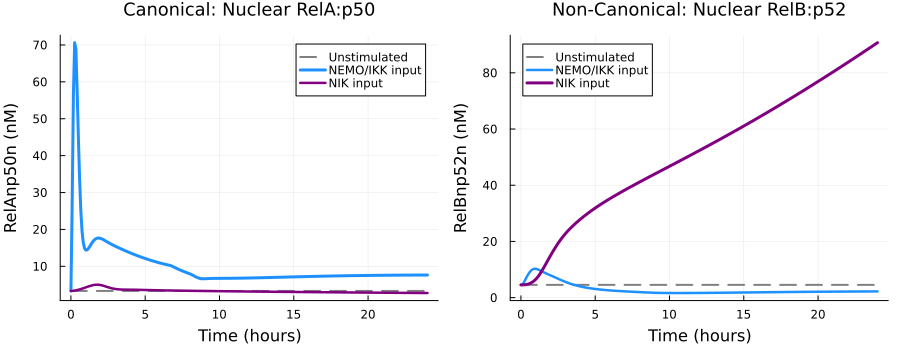

In [5]:
# Clean reusable helper: runs Phase 2 from a given steady state y0 with chosen IKK & NIK curves
function run_nfkb_timecourse(y0_start, ikk_curve, nik_curve;
                             hours=24.0, param_scales=Dict{String,Float64}())
    p_run = copy(paramVals)
    for (pname, factor) in param_scales
        idx = findfirst(x -> x == pname, parameterNameList)
        isnothing(idx) && error("Parameter \"$pname\" not found in parameterNameList!")
        p_run[idx] = p_run[idx] * factor
    end
    p_run[ikkIndex] = ikk_curve
    p_run[nikIndex] = nik_curve

    prob = ODEProblem(ODEFunction(nfkbModel), copy(y0_start), (0.0, hours * 60.0), p_run)
    return solve(prob, stiff_alg; abstol=1e-6, reltol=1e-4, saveat=5.0)
end

# Run all 3 conditions from the exact same resting steady state!
sol_ctrl = run_nfkb_timecourse(y0_ss, ikkSS, nikSS; hours=24.0)
sol_ikk  = run_nfkb_timecourse(y0_ss, ikkTC, nikSS; hours=24.0)
sol_nik  = run_nfkb_timecourse(y0_ss, ikkSS, nikTC; hours=24.0)

hrs = sol_ctrl.t ./ 60.0

p_rela = plot(hrs, sol_ctrl[idx_RelAp50, :], label="Unstimulated", lw=2.0, ls=:dash, color=:gray,
              title="Canonical: Nuclear RelA:p50", titlefontsize=12,
              xlabel="Time (hours)", ylabel="RelAnp50n (nM)")
plot!(p_rela, hrs, sol_ikk[idx_RelAp50, :], label="NEMO/IKK input", lw=3.0, color=:dodgerblue)
plot!(p_rela, hrs, sol_nik[idx_RelAp50, :], label="NIK input", lw=2.5, color=:purple)

p_relb = plot(hrs, sol_ctrl[idx_RelBp52, :], label="Unstimulated", lw=2.0, ls=:dash, color=:gray,
              title="Non-Canonical: Nuclear RelB:p52", titlefontsize=12,
              xlabel="Time (hours)", ylabel="RelBnp52n (nM)")
plot!(p_relb, hrs, sol_ikk[idx_RelBp52, :], label="NEMO/IKK input", lw=2.5, color=:dodgerblue)
plot!(p_relb, hrs, sol_nik[idx_RelBp52, :], label="NIK input", lw=3.0, color=:purple)

plot(p_rela, p_relb, layout=(1, 2), size=(900, 360))

These two panels show the distinct dynamics of the canonical and non-canonical NF-κB pathways in the published 101-species model:

- **Left panel (`RelAnp50n`):** Under **NEMO/IKK input** (blue), nuclear **RelA:p50** rises rapidly within the first hour as IκBα is degraded, then adapts downward as newly induced IκBα sequesters it back out of the nucleus. Under **NIK input** alone (purple), RelA:p50 remains close to baseline.
- **Right panel (`RelBnp52n`):** Under **NIK input** (purple), blocking NIK degradation allows NIK to accumulate, process `p100` into `p52`, and drive a sustained increase in nuclear **RelB:p52** over 24 hours. Under **NEMO/IKK input** alone (blue), RelB:p52 stays near baseline.

---

## Interactive Challenges on the Published NF-κB Model

Try modifying the inputs and parameters yourself in the exercises below.

### Challenge 1: Co-Stimulation — What Happens When Both NEMO/IKK and NIK Fire Together?

In real B-cells (and lymphomas!), cells often receive canonical **NEMO/IKK** and non-canonical **NIK** signals *simultaneously*.

**Your task:** Edit the cell below to add a **co-stimulation** simulation (`sol_both`) passing **both `ikkTC` and `nikTC`**, and overlay it onto the `RelAnp50n` and `RelBnp52n` plots!
Does co-stimulation simply add the two curves together, or do the pathways **cross-talk** (especially in `RelBnp52n`)?

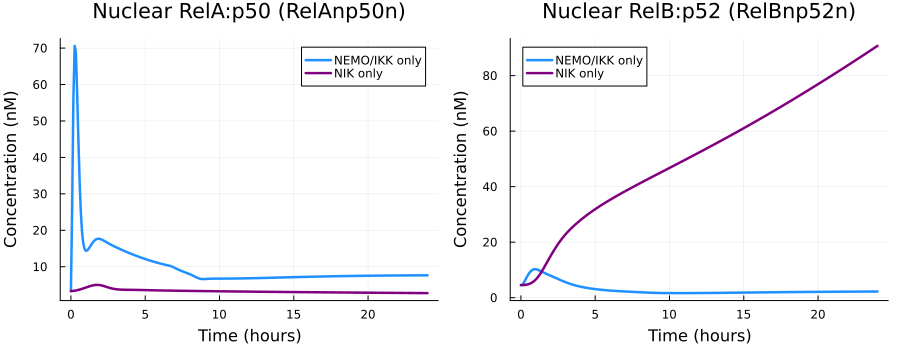

In [6]:
# Challenge 1: Add sol_both = run_nfkb_timecourse(y0_ss, ikkTC, nikTC; hours=24.0) and plot it!
p_c1_a = plot(hrs, sol_ikk[idx_RelAp50, :], label="NEMO/IKK only", lw=2.5, color=:dodgerblue,
              title="Nuclear RelA:p50 (RelAnp50n)", xlabel="Time (hours)", ylabel="Concentration (nM)")
plot!(p_c1_a, hrs, sol_nik[idx_RelAp50, :], label="NIK only", lw=2.5, color=:purple)

p_c1_b = plot(hrs, sol_ikk[idx_RelBp52, :], label="NEMO/IKK only", lw=2.5, color=:dodgerblue,
              title="Nuclear RelB:p52 (RelBnp52n)", xlabel="Time (hours)", ylabel="Concentration (nM)")
plot!(p_c1_b, hrs, sol_nik[idx_RelBp52, :], label="NIK only", lw=2.5, color=:purple)

# TODO: run sol_both with BOTH ikkTC and nikTC, and add plot!(...) calls for both panels!

plot(p_c1_a, p_c1_b, layout=(1, 2), size=(900, 360))

````{admonition} Hint
:class: dropdown tip

Add one line to simulate co-stimulation:
```julia
sol_both = run_nfkb_timecourse(y0_ss, ikkTC, nikTC; hours=24.0)
```
Then add `plot!(p_c1_a, hrs, sol_both[idx_RelAp50, :], label="NEMO/IKK + NIK", lw=3.0, color=:crimson)` and the matching line for `p_c1_b` (`idx_RelBp52`).
````

````{admonition} Reveal Solution & Biological Insight
:class: dropdown note

```julia
sol_both = run_nfkb_timecourse(y0_ss, ikkTC, nikTC; hours=24.0)

p_c1_a = plot(hrs, sol_ikk[idx_RelAp50, :],  label="NEMO/IKK only",  lw=2.5, color=:dodgerblue,
              title="Nuclear RelA:p50 (RelAnp50n)", xlabel="Time (hours)", ylabel="Concentration (nM)")
plot!(p_c1_a, hrs, sol_nik[idx_RelAp50, :],  label="NIK only",       lw=2.5, color=:purple)
plot!(p_c1_a, hrs, sol_both[idx_RelAp50, :], label="NEMO/IKK + NIK", lw=3.0, color=:crimson, ls=:dash)

p_c1_b = plot(hrs, sol_ikk[idx_RelBp52, :],  label="NEMO/IKK only",  lw=2.5, color=:dodgerblue,
              title="Nuclear RelB:p52 (RelBnp52n)", xlabel="Time (hours)", ylabel="Concentration (nM)")
plot!(p_c1_b, hrs, sol_nik[idx_RelBp52, :],  label="NIK only",       lw=2.5, color=:purple)
plot!(p_c1_b, hrs, sol_both[idx_RelBp52, :], label="NEMO/IKK + NIK", lw=3.0, color=:crimson)

plot(p_c1_a, p_c1_b, layout=(1, 2), size=(900, 360))
```

**Pathway cross-talk:** Notice that **NEMO/IKK + NIK** produces more nuclear **RelB:p52** than NIK alone. Canonical RelA:p50 transcriptionally induces additional **`p100` (NFKB2)** and **`RelB`** mRNA, supplying the stabilised NIK with more `p100` substrate to process into `p52`.
````

---

### Challenge 2: Test a Gradual / Partial NIK Input Curve!

In real cells, a non-canonical receptor signal rarely drops NIK degradation instantaneously to `0.0` at `t = 0`. Remember the smooth decay curve from Chapter 2?

$$\text{nikSmooth}(t) = \frac{1}{1 + t / 60}$$

And what about a **partial** block that only cuts NIK degradation in half (`nikHalf = t -> 0.5`)?

**Your task:** Edit the cell below to compare **three NIK input curves** — `nikTC` (`t -> 0.0`), `nikSmooth` (`t -> 1 / (1 + t/60)`), and `nikHalf` (`t -> 0.5`) — and plot both the input curves and the resulting nuclear **`RelBnp52n`**!

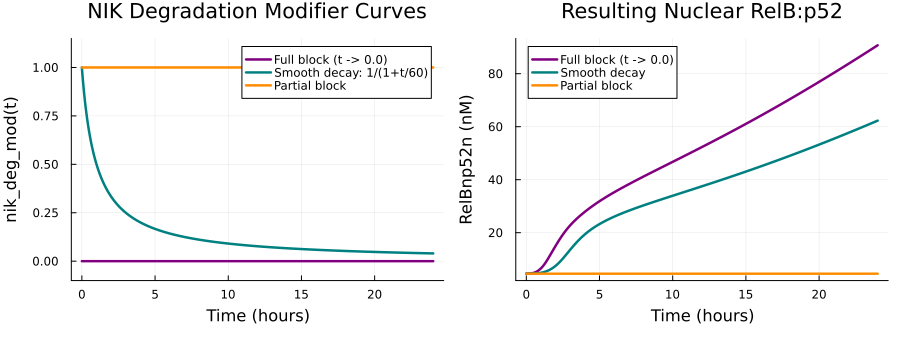

In [7]:
# Challenge 2: Define nikSmooth and nikHalf, simulate them, and compare RelBnp52n!
nikSmooth = t -> 1.0 / (1.0 + t / 60.0)
nikHalf   = t -> 1.0   # <-- Change this to 0.5 for a 50% block of NIK degradation!

sol_nik_smooth = run_nfkb_timecourse(y0_ss, ikkSS, nikSmooth; hours=24.0)
sol_nik_half   = run_nfkb_timecourse(y0_ss, ikkSS, nikHalf;   hours=24.0)

p_in = plot(t_hrs, nikTC.(t_mins), lw=2.5, color=:purple, label="Full block (t -> 0.0)",
            title="NIK Degradation Modifier Curves", xlabel="Time (hours)", ylabel="nik_deg_mod(t)", ylim=(-0.1, 1.15))
plot!(p_in, t_hrs, nikSmooth.(t_mins), lw=2.5, color=:teal, label="Smooth decay: 1/(1+t/60)")
plot!(p_in, t_hrs, nikHalf.(t_mins),   lw=2.5, color=:darkorange, label="Partial block")

p_out = plot(hrs, sol_nik[idx_RelBp52, :], lw=2.5, color=:purple, label="Full block (t -> 0.0)",
             title="Resulting Nuclear RelB:p52", xlabel="Time (hours)", ylabel="RelBnp52n (nM)")
plot!(p_out, hrs, sol_nik_smooth[idx_RelBp52, :], lw=2.5, color=:teal, label="Smooth decay")
plot!(p_out, hrs, sol_nik_half[idx_RelBp52, :],   lw=2.5, color=:darkorange, label="Partial block")

plot(p_in, p_out, layout=(1, 2), size=(900, 340))

```{admonition} Hint
:class: dropdown tip

Change `nikHalf = t -> 1.0` to `nikHalf = t -> 0.5` and re-run! Notice how `nikSmooth` closely approaches the full block after a few hours (since $\frac{1}{1 + t/60}$ drops below 0.1 after 9 hours), whereas a 50% partial block gives a much more modest `RelBnp52n` increase!
```

````{admonition} Reveal Solution
:class: dropdown note

```julia
nikSmooth = t -> 1.0 / (1.0 + t / 60.0)
nikHalf   = t -> 0.5

sol_nik_smooth = run_nfkb_timecourse(y0_ss, ikkSS, nikSmooth; hours=24.0)
sol_nik_half   = run_nfkb_timecourse(y0_ss, ikkSS, nikHalf;   hours=24.0)

p_in = plot(t_hrs, nikTC.(t_mins), lw=2.5, color=:purple, label="Full block (t -> 0.0)",
            title="NIK Degradation Modifier Curves", xlabel="Time (hours)", ylabel="nik_deg_mod(t)", ylim=(-0.1, 1.15))
plot!(p_in, t_hrs, nikSmooth.(t_mins), lw=2.5, color=:teal, label="Smooth decay: 1/(1+t/60)")
plot!(p_in, t_hrs, nikHalf.(t_mins),   lw=2.5, color=:darkorange, label="Partial block (0.5)")

p_out = plot(hrs, sol_nik[idx_RelBp52, :], lw=2.5, color=:purple, label="Full block (t -> 0.0)",
             title="Resulting Nuclear RelB:p52", xlabel="Time (hours)", ylabel="RelBnp52n (nM)")
plot!(p_out, hrs, sol_nik_smooth[idx_RelBp52, :], lw=2.5, color=:teal, label="Smooth decay")
plot!(p_out, hrs, sol_nik_half[idx_RelBp52, :],   lw=2.5, color=:darkorange, label="Partial block (0.5)")

plot(p_in, p_out, layout=(1, 2), size=(900, 340))
```
````

---

### Challenge 3: Change a Biological Parameter at Run-Time (Just Like Jayawant *et al.*!)

In [`SiFTW/NFkBModel`](https://github.com/SiFTW/NFkBModel), different lymphoma cell lines have different expression rates of NF-κB subunits — for example, elevated **`k1_RelASynth`** (more RelA production) or elevated **`basal_RelBSynth`** (more RelB production).

:::{important} Remember to re-run Steady State when changing an intrinsic cell parameter!
When you only change an *external stimulus* (like `ikkTC` vs `nikTC`), the cell starts from the same resting steady state `y0_ss`.
When you change an **intrinsic cell property** (like a mutation or gene overexpression such as `k1_RelASynth` × 3), that cell has lived with the change its whole life — so you should apply the parameter change in **both Phase 1 (Steady State) and Phase 2 (Time Course)**!
:::

**Your task:** Edit the `param_scales` dictionary in the cell below to simulate a cell with **3× higher `k1_RelASynth`** (or try **`basal_RelBSynth` × 3.0** under NIK stimulation!) at run-time — without regenerating `nfkbModel.jl`!

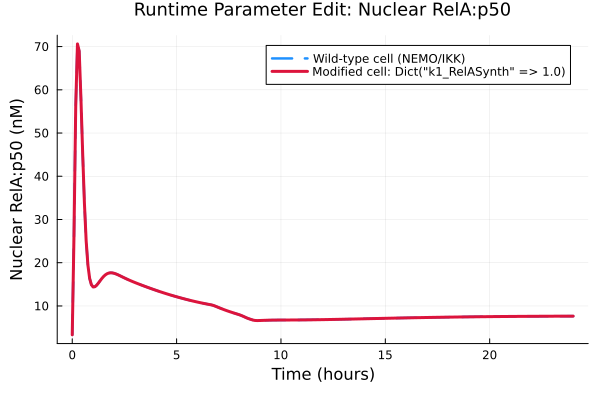

In [8]:
# Helper that runs BOTH Steady State and Time Course with runtime parameter changes
function run_full_cell(ikk_curve, nik_curve; hours=24.0, param_scales=Dict{String,Float64}())
    # Phase 1: Steady state for this modified cell
    p_cell_ss = copy(paramVals)
    for (pname, factor) in param_scales
        idx = findfirst(x -> x == pname, parameterNameList)
        isnothing(idx) && error("Parameter \"$pname\" not found in parameterNameList!")
        p_cell_ss[idx] = p_cell_ss[idx] * factor
    end
    p_cell_ss[ikkIndex] = ikkSS
    p_cell_ss[nikIndex] = nikSS

    sol_cell_ss = solve(ODEProblem(ODEFunction(nfkbModel), zeros(length(syms)), (0.0, maxTimeSS), p_cell_ss),
                        stiff_alg; saveat=1000.0)
    y0_cell = max.(collect(Float64, sol_cell_ss.u[end]), 0.0)

    # Phase 2: Dynamic time course starting from this cell's own steady state
    return run_nfkb_timecourse(y0_cell, ikk_curve, nik_curve; hours=hours, param_scales=param_scales)
end

# Challenge 3: Change 1.0 -> 3.0 for "k1_RelASynth" (or try "basal_RelBSynth" => 3.0 with nikTC!)
my_changes = Dict("k1_RelASynth" => 1.0)

sol_mod_ikk = run_full_cell(ikkTC, nikSS; hours=24.0, param_scales=my_changes)

plot(hrs, sol_ikk[idx_RelAp50, :],     label="Wild-type cell (NEMO/IKK)", lw=2.5, ls=:dash, color=:dodgerblue,
     xlabel="Time (hours)", ylabel="Nuclear RelA:p50 (nM)",
     title="Runtime Parameter Edit: Nuclear RelA:p50", titlefontsize=12)
plot!(hrs, sol_mod_ikk[idx_RelAp50, :], label="Modified cell: $(my_changes)", lw=3.0, color=:crimson)

```{admonition} Hint
:class: dropdown tip

Change `my_changes = Dict("k1_RelASynth" => 1.0)` to `my_changes = Dict("k1_RelASynth" => 3.0)` and re-run!
Want to test the non-canonical pathway too? Try `my_changes = Dict("basal_RelBSynth" => 3.0)` with `run_full_cell(ikkSS, nikTC; ...)` and plot `idx_RelBp52`!
```

````{admonition} Reveal Solution
:class: dropdown note

```julia
# Example 1: 3x RelA synthesis under canonical NEMO/IKK stimulation
sol_rela3x = run_full_cell(ikkTC, nikSS; hours=24.0, param_scales=Dict("k1_RelASynth" => 3.0))

# Example 2: 3x RelB synthesis under non-canonical NIK stimulation
sol_relb3x = run_full_cell(ikkSS, nikTC; hours=24.0, param_scales=Dict("basal_RelBSynth" => 3.0))

p1 = plot(hrs, sol_ikk[idx_RelAp50, :],    label="Wild-type (NEMO/IKK)", lw=2.5, ls=:dash, color=:dodgerblue,
          title="3× RelA Synthesis → RelA:p50", xlabel="Time (hours)", ylabel="RelAnp50n (nM)")
plot!(p1, hrs, sol_rela3x[idx_RelAp50, :], label="3× k1_RelASynth",      lw=3.0, color=:crimson)

p2 = plot(hrs, sol_nik[idx_RelBp52, :],    label="Wild-type (NIK)",      lw=2.5, ls=:dash, color=:purple,
          title="3× RelB Synthesis → RelB:p52", xlabel="Time (hours)", ylabel="RelBnp52n (nM)")
plot!(p2, hrs, sol_relb3x[idx_RelBp52, :], label="3× basal_RelBSynth",   lw=3.0, color=:darkorange)

plot(p1, p2, layout=(1, 2), size=(900, 340))
```
````

---

## Summary

In Tutorial 3, you have learned how to:
- Write and debug `CSV2Julia` tables using positional species placeholders (`[S1]`, `[Mod1]`) and the underscore naming rule (`prefix_uniqueLabel`).
- Use **`inline`**, **`scan`**, and **`param`** modes, and modify parameters at run-time with `copy(paramVals)` and `findfirst(...)`.
- Build **time-dependent input curves** (constant, pulse, smooth decay, and linearly interpolated experimental curves) and connect them into `CSV2Julia` via `(t)`.
- Generate and simulate the published **101-species, 257-parameter NF-κB model** ([`SiFTW/NFkBModel`](https://github.com/SiFTW/NFkBModel)) in two phases (Steady State → Time Course), using **NEMO/IKK** and **NIK** inputs to activate nuclear **RelA:p50** and **RelB:p52** respectively.

:::{tip} Next Up (Tutorial 4)
Continue to **[Tutorial 4: Combining Modules into the BCR–TLR–NF-κB Tri-Model](../tutorial-4/01-combining-modules.ipynb)** to combine multiple upstream receptor modules (`BCR`, `TLR`, `NFkB`, and `linking`), simulate heterogeneous cell populations, and recreate **Figure 5 of Jayawant *et al.***.
:::